In [ ]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import cv2

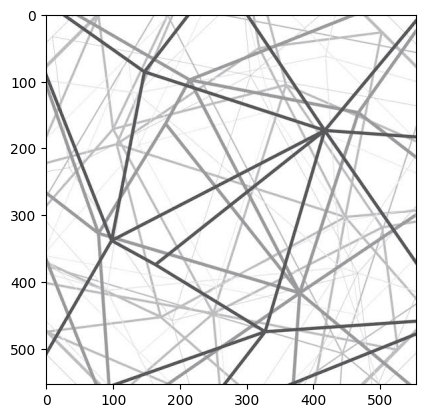

In [ ]:
image_path = "/content/Lines.jpg"
image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(image)
plt.show()

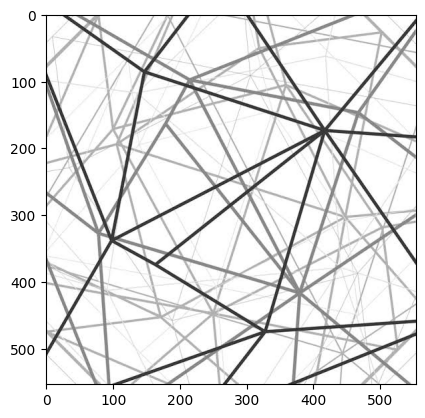

In [ ]:
def conver_im_toGray(image):
  if image.ndim == 3:
     return cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
  else:
    return image


grey_image = conver_im_toGray(image)
plt.imshow(grey_image, cmap='gray')
plt.show()

In [ ]:
ALLOWED_KERNEL_SOZES = [3,5,7,9,15]

def validate_kernel_size(kernel_size):
  if kernel_size in ALLOWED_KERNEL_SOZES:
    return True
  else:
    return False

def gaussian_kernel(image_dim, kernel_size, sigma):
  n,m = image_dim
  if  n < kernel_size or m < kernel_size:
    raise TypeError("The image size is smaller than the kernel size")
  elif not validate_kernel_size(kernel_size):
    raise TypeError("The kernel size is not allowed")
  else:
    epsilon = 1e-5
    center = kernel_size // 2
    x, y = np.meshgrid(np.linspace(-center, center, kernel_size), np.linspace(-center, center, kernel_size))
    gaussian_kernel = np.exp(-(x**2 + y**2) / (2 * sigma**2 + epsilon))
    return gaussian_kernel / np.sum(gaussian_kernel)


# try :
#   user_input = int(input(" Kernel size : "))
#   sigma = int(input("sigme : "))
#   print(gaussian_kernel(grey_image.shape, user_input, sigma))
# except Exception as e:
#   print(e)



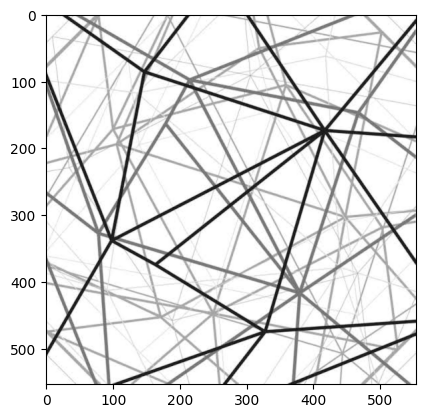

In [ ]:
def convolution(image, kernel):
    n, m = len(image), len(image[0])
    x, y = len(kernel), len(kernel[0])

    out_n, out_m = n - x + 1, m - y + 1
    convolved_image = [[0.0] * out_m for _ in range(out_n)]

    for i in range(out_n):
        for j in range(out_m):
            total = 0.0
            for u in range(x):
                for v in range(y):
                    total += image[i + u][j + v] * kernel[x - 1 - u][y - 1 - v]
            convolved_image[i][j] = total

    return convolved_image

def _pad(image, kernel_size):
  p = kernel_size // 2
  return np.pad(image.astype(np.float64), p, mode='reflect')
def gaussian_blur(image, kernel_size, sigma):
  kernel = gaussian_kernel(image.shape, kernel_size, sigma)
  padded = _pad(image, kernel_size)
  result = convolution(padded.tolist(), kernel.tolist())
  return np.array(result)
blured_image = gaussian_blur(grey_image, 3, .5)
plt.imshow(blured_image, cmap='gray')
plt.show()

Text(0.5, 1.0, 'Orientation')

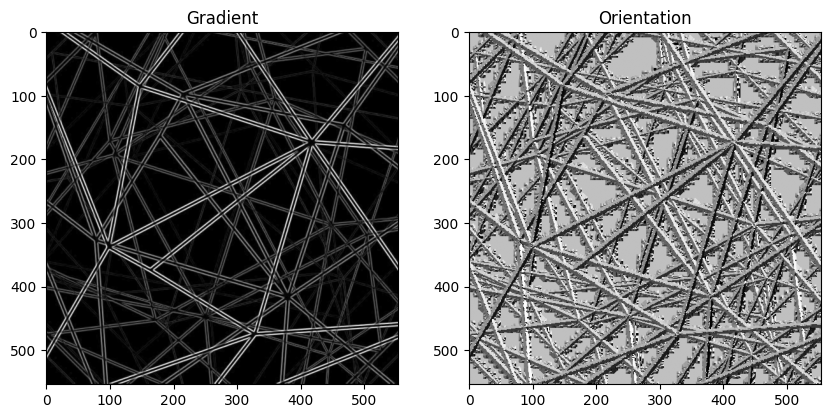

In [ ]:
SOBEL_X = np.array([[1, 0, -1]
                    , [2, 0, -2]
                    , [1, 0, -1]])
SOBEL_Y = np.array([[1, 2, 1]
                    , [0, 0, 0]
                    , [-1, -2, -1]])

def apply_sobel(blured_image):
  padded = _pad(blured_image, 3)
  sobel_x = convolution(padded.tolist(), SOBEL_X.tolist())
  sobel_y = convolution(padded.tolist(), SOBEL_Y.tolist())
  gradient = np.sqrt(np.array(sobel_x) ** 2 + np.array(sobel_y) ** 2)
  orientation = np.arctan2(np.array(sobel_y), np.array(sobel_x))
  angle_360 = np.degrees(orientation) % 360
  return gradient, angle_360

Gradient, angles = apply_sobel(blured_image)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(Gradient, cmap='gray')
axes[0].set_title('Gradient')
axes[1].imshow(angles, cmap='gray')
axes[1].set_title('Orientation')


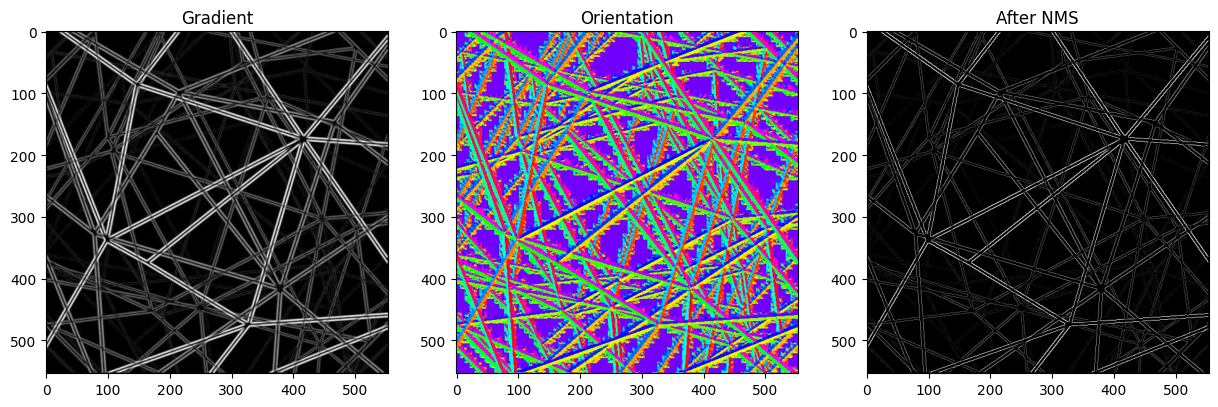

In [ ]:
def non_maximum_suppression(Gradient, orientation):  # orientation   min : 0  , max 360
    n, m = Gradient.shape
    suppressed = [[0.0] * m for _ in range(n)]
    G = Gradient.tolist()
    A = orientation.tolist()
    for i in range(1, n - 1):
        for j in range(1, m - 1):
            angle = A[i][j] % 180
            grad = G[i][j]
            if angle < 22.5 or angle >=157.5:
              n1, n2 = G[i][j - 1], G[i][j + 1]
            elif angle < 67.5:
              n1, n2 = G[i - 1][j - 1], G[i + 1][j + 1]
            elif angle < 112.5:
              n1, n2 = G[i - 1][j], G[i + 1][j]
            else:
              n1, n2  = G[i - 1][j + 1],  G[i + 1][j - 1]
            if grad >= max(n1, n2):
                suppressed[i][j] = grad
            else:
                suppressed[i][j] = 0.0
    return np.array(suppressed)
blured_image = gaussian_blur(grey_image, 3, 10)
Gradient, angles = apply_sobel(blured_image)
suppressed = non_maximum_suppression(Gradient, angles)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(Gradient, cmap='gray')
axes[0].set_title('Gradient')
axes[1].imshow(angles, cmap='hsv', vmin=0, vmax=360)
axes[1].set_title('Orientation')
axes[2].imshow(suppressed, cmap='gray')
axes[2].set_title('After NMS')
plt.show()

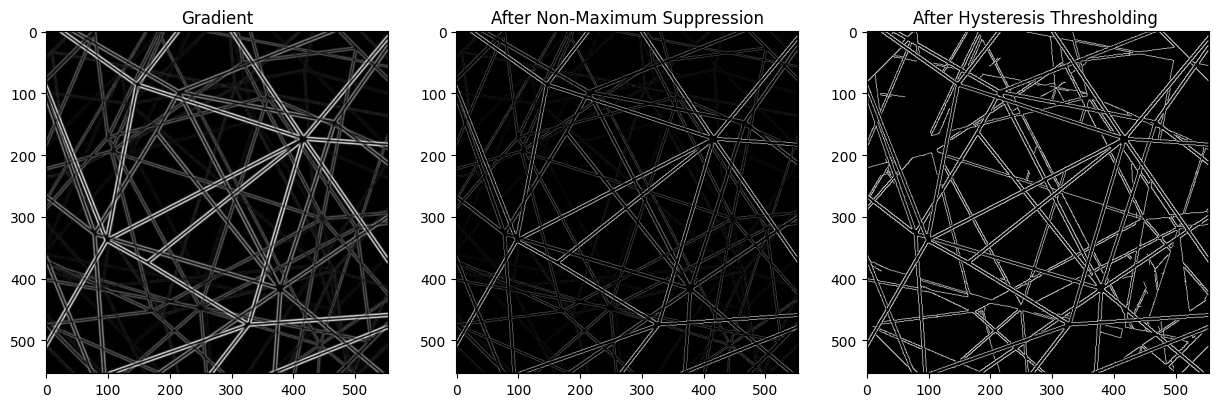

In [ ]:
def hysteresis_thresholding(image, high_threshold, low_threshold):
    G = image.tolist()
    n, m = len(G), len(G[0])
    result = [[0.0] * m for _ in range(n)]

    # 1) seeds: all strong pixels
    stack = []
    for i in range(n):
        for j in range(m):
            if G[i][j] >= high_threshold:
                result[i][j] = 255.0
                stack.append((i, j))

    # 2) grow: add weak pixels connected (8-neighborhood) to anything already kept
    while stack:
        i, j = stack.pop()
        for di in (-1, 0, 1):
            for dj in (-1, 0, 1):
                r, c = i + di, j + dj
                if 0 <= r < n and 0 <= c < m \
                   and result[r][c] == 0.0 and G[r][c] >= low_threshold:
                    result[r][c] = 255.0
                    stack.append((r, c))

    return np.array(result)

low_threshold = 50
high_threshold = 300
sigma = .7
kernel_size = 7
blured_image = gaussian_blur(grey_image, kernel_size, sigma)
Gradient, angles = apply_sobel(blured_image)
suppressed = non_maximum_suppression(Gradient, angles)
hysteresis_image = hysteresis_thresholding(suppressed, high_threshold, low_threshold)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(Gradient, cmap='gray')
axes[0].set_title('Gradient')
axes[1].imshow(suppressed, cmap='gray')
axes[1].set_title('After Non-Maximum Suppression')
axes[2].imshow(hysteresis_image, cmap='gray')
axes[2].set_title('After Hysteresis Thresholding ')
plt.show()

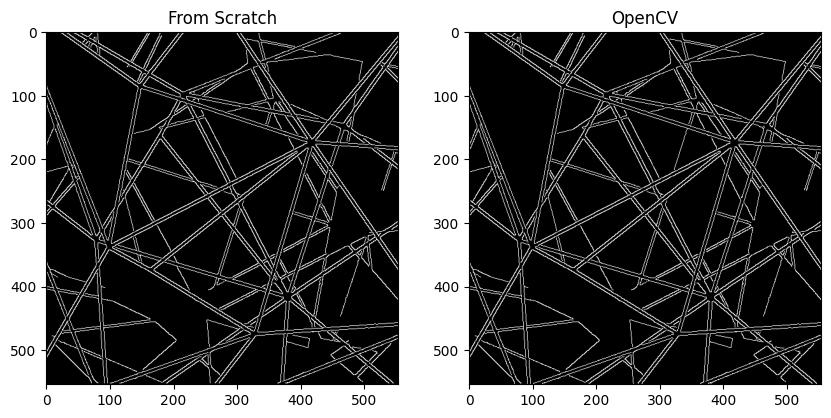

In [ ]:
def canny_edge_detector(image, kernel_size, sigma, high_threshold, low_threshold):
    blured_image = gaussian_blur(image, kernel_size, sigma)
    Gradient, angles = apply_sobel(blured_image)
    suppressed = non_maximum_suppression(Gradient, angles)
    return hysteresis_thresholding(suppressed, high_threshold, low_threshold)
low_threshold = 80
high_threshold = 200
sigma = 1
kernel_size = 7

from_scratch_canny = canny_edge_detector(grey_image, kernel_size, sigma, high_threshold , low_threshold)
blurred_u8 = gaussian_blur(grey_image, kernel_size, sigma).astype(np.uint8)
cv_canny = cv2.Canny(blurred_u8, threshold1=low_threshold, threshold2=high_threshold,L2gradient=True)

fig, axes = plt.subplots(1, 2, figsize=(10,15))
axes[0].imshow(from_scratch_canny, cmap='gray')
axes[0].set_title('From Scratch')
axes[1].imshow(cv_canny, cmap='gray')
axes[1].set_title('OpenCV')
plt.show()

In [ ]:
def Hough_transform(edges, radius_res, theta_res):
    h, w = edges.shape
    max_r = np.sqrt(h**2 + w**2)

    radius = np.arange(-max_r, max_r + radius_res, radius_res)
    theta  = np.arange(0, 180, theta_res)

    cos = np.cos(np.deg2rad(theta)).tolist()
    sin = np.sin(np.deg2rad(theta)).tolist()
    acc = [[0] * len(theta) for _ in range(len(radius))]
    E = edges.tolist()
    n_theta = len(theta)

    for y in range(h):
        for x in range(w):
            if E[y][x] != 0:
                for k in range(n_theta):
                    idx = int(round((x * cos[k] + y * sin[k] + max_r) / radius_res))
                    acc[idx][k] += 1

    return np.array(acc), radius, theta

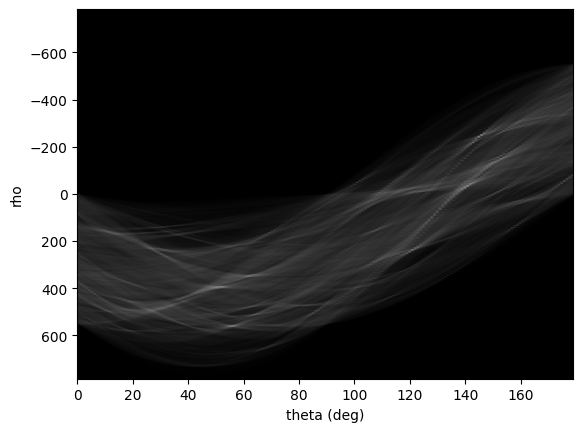

In [ ]:
low_threshold = 80
high_threshold = 200
sigma = 1
kernel_size = 7
from_scratch_canny = canny_edge_detector(grey_image, kernel_size, sigma, high_threshold , low_threshold)


radius_res = 1
theta_res = 1
acc, radius, theta = Hough_transform(from_scratch_canny, radius_res=radius_res, theta_res=theta_res)



plt.imshow(acc, cmap='gray', aspect='auto',
           extent=[theta[0], theta[-1], radius[-1], radius[0]])
plt.xlabel('theta (deg)'); plt.ylabel('rho')
plt.show()

In [ ]:
def find_peaks(acc, vote_threshold, neighborhood=10, max_lines=10):
    A = acc.tolist()
    n_r, n_t = len(A), len(A[0])
    candidates = []

    for i in range(n_r):
        for j in range(n_t):
            v = A[i][j]
            if v < vote_threshold:
                continue
            is_peak = True
            for di in range(-neighborhood, neighborhood + 1):
                for dj in range(-neighborhood, neighborhood + 1):
                    r, c = i + di, j + dj
                    if 0 <= r < n_r and 0 <= c < n_t and A[r][c] > v:
                        is_peak = False
                        break
                if not is_peak:
                    break
            if is_peak:
                candidates.append((v, i, j))

    candidates.sort(reverse=True)
    return candidates[:min(max_lines, len(candidates)-1)]

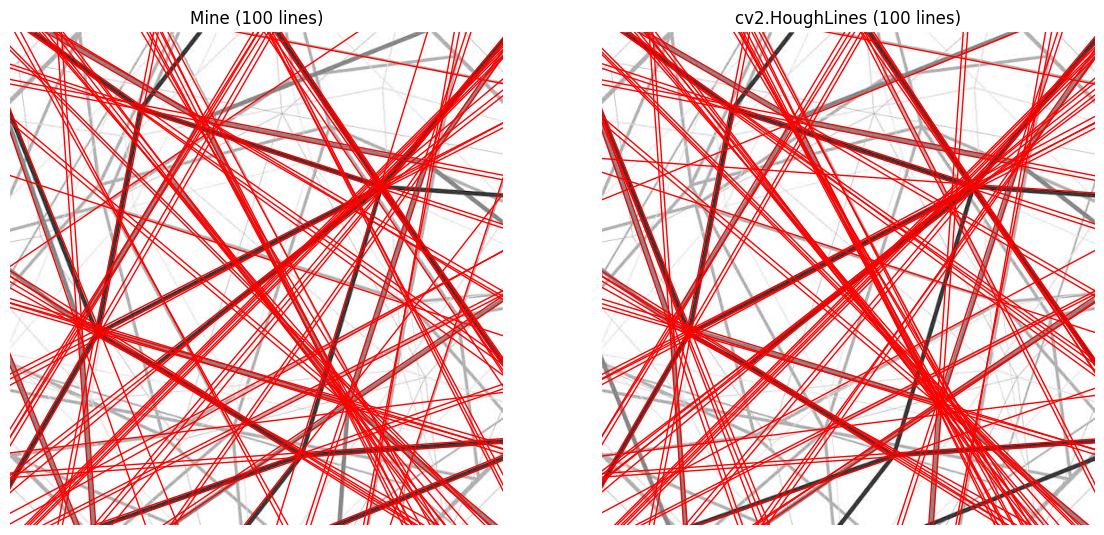

mine (rho, theta°): [(-246, 146), (-251, 146), (393, 52), (-43, 142), (561, 56)]
cv2  (rho, theta°): [(39, 108), (34, 108), (-251, 146), (-246, 146), (556, 56)]


In [ ]:
def draw_lines(ax, image, lines, title):
    """lines: list of (rho, theta_in_radians). Draws them over the image on ax."""
    h, w = image.shape[:2]
    L = np.sqrt(h**2 + w**2)
    ax.imshow(image, cmap='gray' if image.ndim == 2 else None)
    for rho, t in lines:
        x0, y0 = rho * np.cos(t), rho * np.sin(t)    # closest point to origin
        dx, dy = -np.sin(t), np.cos(t)               # direction along the line
        ax.plot([x0 - L * dx, x0 + L * dx],
                [y0 - L * dy, y0 + L * dy], 'r-', linewidth=1)
    ax.set_xlim(0, w); ax.set_ylim(h, 0)             # y points down
    ax.axis('off')
    ax.set_title(f"{title} ({len(lines)} lines)")


# ---- edges ----
low_threshold, high_threshold = 80, 200
sigma, kernel_size = 1, 7
from_scratch_canny = canny_edge_detector(grey_image, kernel_size, sigma,
                                         high_threshold, low_threshold)

# ---- mine ----
radius_res, theta_res = 1, 1
acc, radius, theta = Hough_transform(from_scratch_canny, radius_res, theta_res)

vote_threshold = 2
neighborhood = 1
max_lines = 100

peaks = find_peaks(acc, vote_threshold, neighborhood, max_lines)
my_lines = [(radius[i], np.deg2rad(theta[j])) for _, i, j in peaks]

# ---- OpenCV (needs uint8 edges, theta in radians) ----
edges_u8 = ((from_scratch_canny > 0) * 255).astype(np.uint8)
cv_out = cv2.HoughLines(edges_u8, radius_res, np.deg2rad(theta_res), vote_threshold)
cv_lines = [] if cv_out is None else [(r, t) for r, t in cv_out[:, 0]]
cv_lines = cv_lines[:max_lines]                      # same cap, strongest first

# ---- compare ----
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
draw_lines(axes[0], grey_image, my_lines, 'Mine')
draw_lines(axes[1], grey_image, cv_lines, 'cv2.HoughLines')
plt.show()

print("mine (rho, theta°):", [(round(float(r)), round(float(np.degrees(t)))) for r, t in my_lines[:5]])
print("cv2  (rho, theta°):", [(round(float(r)), round(float(np.degrees(t)))) for r, t in cv_lines[:5]])